In [ ]:
import pathlib

import marimo as mo
from matplotlib import pyplot as plt
import numpy as np
from teeplot import teeplot as tp
from watermark import watermark

from pylib.theory._calc_invader_fixprob_closed import (
    calc_invader_fixprob_closed,
)

In [ ]:
mo.md(
    f"""
```Text
{watermark(
    current_date=True,
    iso8601=True,
    machine=True,
    updated=True,
    python=True,
    iversions=True,
    globals_=globals(),
)}
```
"""
)

```Text
Last updated: 2026-11-25T20:45:09.444168+00:00

Python implementation: CPython
Python version       : 3.10.12
IPython version      : 7.31.1

Compiler    : GCC 11.4.0
OS          : Linux
Release     : 6.8.0-1070-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 4
Architecture: 64bit

matplotlib: 3.9.2
numpy     : 2.1.2
marimo    : 0.23.2
teeplot   : 1.2.0

```

In [ ]:
teeplot_subdir = pathlib.Path(__file__).stem
teeplot_subdir

'theory-invader-npfix'

# A single invading mutator under limited adaptive potential

Figure 1 of [Raynes et al. (2018)](https://doi.org/10.1073/pnas.1715996115) plots normalized fixation probability $N P_\mathrm{fix}$ of a single mutator lineage against population size $N$.
Mutators are disfavored ($N P_\mathrm{fix} < 1$) in small populations and favored in large ones.

Here we redraw that figure for this project's simulation parameters and add curves for limited adaptive potential, where only one or two beneficial mutations are available.
Each limited curve is the unlimited curve times the probability that mutators hold their lead until nonmutators are gone (`calc_invader_hold_prob_closed`),

$$N P_\mathrm{fix} = N \, P_\mathrm{escape}(N) \, P_\mathrm{hold}(N, K).$$

Limited adaptive potential leaves small populations untouched but disfavors mutators again in large ones.

These curves are closed-form predictions; they have not been checked against simulations started from a single mutator.

In [ ]:
model_N = np.geomspace(1.5, 1e7, 500)
model_npfix = {
    K: np.array([N * calc_invader_fixprob_closed(N, K) for N in model_N])
    for K in (np.inf, 1, 2)
}

In [ ]:
{
    K: (
        float(npfix.max()),
        float(model_N[npfix.argmax()]),
        model_N[
            np.flatnonzero((npfix[:-1] > 1) & (npfix[1:] <= 1))
        ].tolist(),
    )
    for K, npfix in model_npfix.items()
}

teeplots/theory-invader-npfix/viz=plot-invader-npfix+ext=.pdf
teeplots/theory-invader-npfix/viz=plot-invader-npfix+ext=.png


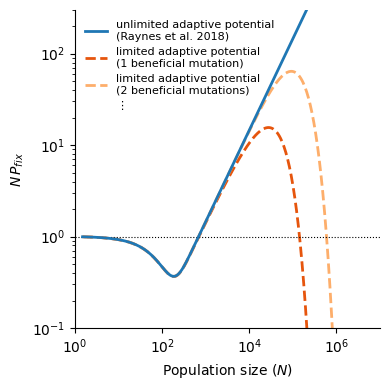

In [ ]:
def plot_invader_npfix() -> plt.Figure:
    fig, ax = plt.subplots(figsize=(4, 4))
    for K, color, linestyle, label in (
        (
            np.inf,
            "tab:blue",
            "-",
            "unlimited adaptive potential\n(Raynes et al. 2018)",
        ),
        (
            1,
            "#e6550d",
            "--",
            "limited adaptive potential\n(1 beneficial mutation)",
        ),
        (
            2,
            "#fdae6b",
            "--",
            "limited adaptive potential\n(2 beneficial mutations)",
        ),
    ):
        ax.plot(
            model_N,
            model_npfix[K],
            color=color,
            label=label,
            linestyle=linestyle,
            linewidth=2,
            zorder=3 if linestyle == "-" else 2,
        )
    ax.plot([], [], " ", label="⋮")  # further mutations, not drawn
    ax.axhline(1, color="black", linestyle=":", linewidth=0.8)
    ax.set(
        xlabel="Population size ($N$)",
        xlim=(1, 1e7),
        xscale="log",
        ylabel="$N\\,P_{fix}$",
        ylim=(0.1, 300),
        yscale="log",
    )
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, loc="upper left", fontsize=8)
    fig.tight_layout()
    return fig

tp.tee(plot_invader_npfix, teeplot_subdir=teeplot_subdir)